# Connections Analysis — simple workflow

The **SQLite database** (`data/raw/connections.db`) is the source of truth. Use `python project.py scrape` to update it from the web; `python project.py build --semantic` to rebuild all analysis tables. The notebook reads the generated tables.

Only **PyTorch** trains predictive neural models. Chronological **80% train / 20% validation**, with **no test split**. sklearn is used for clustering and descriptive analysis only.


## FAIR Principles

F - Findable: The project is findable as the repository exists publicly on github. The project could theoretically become more findable by uploading it to Zenodo, but we simply chose not to do this.

A - Accessible: The code is accessible via github, both the data scraper as well as the analysis/code. 

I - Interoperable: We added a "Requirements" file in order to showcase what is needed to run the code. If these requirements are fulfilled, there should not be a problem in executing the code on another machine.

R - Reproducible: We created a reproducible workflow in which we outlined the steps necessary to reach our results. The code is also somewhat annotated in order to more easily allow other people to understand the code

## What is connections?

Connections is a playable daily game featured on the website https://www.nytimes.com/games/connections. The game involves 16 words, each word belonging to one of 4 "hidden" categories. The categories are also divided into different difficulties, with Yellow being the easiest category and Purple being the hardest. The player's task is to correctly guess which of the 16 words belong together in these groups of four. Once all 16 words have been placed into the correct category (or the player fails to correctly guess the correct category), the game ends.

## 1. Load data

Run `python project.py scrape --start YYYY-MM-DD --end YYYY-MM-DD` in a terminal if you need to collect new dates, then `python project.py build --semantic`. The scraper depends on a third-party website and may need updating if its layout changes.

In [1]:
from IPython.display import display
from connections.data import load_data, puzzle_examples, quality_report, puzzle_features
from connections.clustering import load_encoder
words, groups, pairs = load_data()
print(f"Puzzles: {words.puzzle_date.nunique():,}")
display(quality_report(words).head())

Puzzles: 1,219


,puzzle_date,word_rows,unique_words,groups,difficulty,valid_shape
0,2023-06-12,16,16,4,NaN,True
1,2023-06-13,16,16,4,NaN,True
2,2023-06-14,16,16,4,NaN,True
3,2023-06-15,16,16,4,NaN,True
4,2023-06-16,16,16,4,NaN,True


## 2. Descriptive analysis

In [2]:
from connections.analysis import difficulty_trends, color_summary, difficulty_correlations, puzzle_structure, vocabulary_tables
puzzles = puzzle_features(words, pairs)
display(difficulty_trends(puzzles))
display(color_summary(groups))
display(difficulty_correlations(puzzles))
coordinates, clusters, variance = puzzle_structure(puzzles)
display(clusters)
word_counts, category_counts = vocabulary_tables(words)
display(word_counts.sort_values("appearances", ascending=False).head(10))

,year,count,mean,median
0,2024,223,2.939462,3.0
1,2025,365,2.742740,2.8
2,2026,285,2.262105,2.3


,color,count,mean,std
0,blue,1219,0.293641,0.068861
1,green,1219,0.316568,0.074187
2,purple,1219,0.263698,0.059121
3,yellow,1219,0.331251,0.081190


,feature,n,spearman_correlation,p_value
0,within_group_similarity,873,0.013368,0.693255
1,cross_group_similarity,873,0.129014,0.000132
2,similarity_gap,873,-0.097495,0.003934
3,mean_word_length,873,-0.122662,0.000280
4,sd_word_length,873,-0.094480,0.005209


,cluster,puzzles,mean_difficulty,mean_within_similarity,mean_cross_similarity
0,0,227,2.564186,0.260916,0.210915
1,1,991,2.659574,0.309833,0.254104
2,2,1,NaN,1.000000,1.000000


,word,appearances,puzzles_used
464,BALL,30,30
6421,RING,25,25
2927,FLY,22,22
504,BAR,22,22
1348,CHECK,21,21
4340,LEAD,20,20
759,BLUE,19,19
4009,JACK,19,19
8642,WING,19,19
7409,STICK,18,18


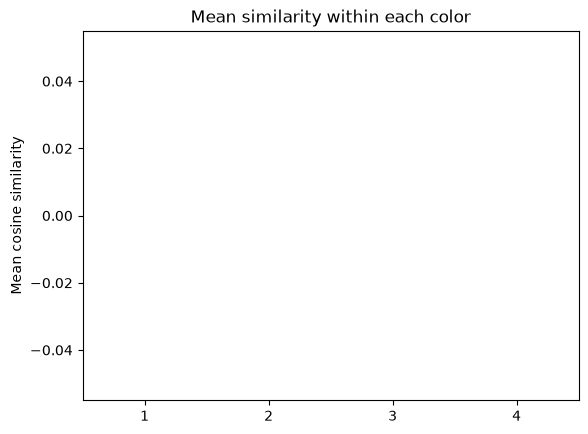

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

groups = pd.read_csv("data/semantic_source/semantic_group_statistics.csv")

mean_sim = groups.groupby("color")["mean_similarity"].mean()
mean_sim = mean_sim.reindex(["1", "2", "3", "4"])

mean_sim.plot(
    kind="bar",
    color=["gold", "green", "royalblue", "purple"]
)

plt.ylabel("Mean cosine similarity")
plt.xlabel("")
plt.title("Mean similarity within each color")
plt.xticks(rotation=0)
plt.show()

## 3. Model justification and limitation

We chose to go with a machine learning approach to try and solve the problem. Mainly, this approach stems from the fact that we thought that it would be an interesting challenge, and the fact we found it interesting to determine if it was at all possible to train a neural network to complete a Connections puzzle.

Many different sizes of networks were used. One more "standard" model was a quite small network with a "Sequential model" (from PyTorch). The input layer is fixed at 768 objects from the semantic descriptor, and the following middle layer was a two-dimensional Linear function with 128 nodes, into a final linear output layer with 128 nodes. A dropout value of $0.2$ was also added. All in all, the models were not tested very extensively, and if we had more time, this would likely be the leading investigative option, to see if we could create a more rigorous set of models, to see if there are some that perform much better than others.

One big hurdle we ran into relatively quickly was the fact that the model was not very good at predicting the correct categories. In the beginning, we simply trained the model on all words (in the training data set), and asked it to evaluate all groups in the validation/test data. This result turned out quite poor, where the model only solved approximately $0.8\%$ of all puzzles. This is still much better than just selecting words at random (\approx 0.00004\%), but compared to human intellect, it is not very impressive. This can also be seen in the below figure, where model starts overtraining after only 10 epochs. We interpreted this as the data (and thus puzzle) being slightly too complicated for a neural network to solve consistently. We therefore decided to simplify the input a bit, in order to see if that would help the network solve the problem more frequently.

![image](Figure_1.png)

Here, we eventually simplified the input so that the model only trained on the easiest category (Yellow). This is mainly because the yellow category more frequently seemed to be semantically related, leading us to believe that we could achieve a better result if the model only had to predict one of the four groups in the puzzle. Using a similar network as for the entire puzzle, the training became something akin to the following picture:

![image](Figure_2.png)

This figure showed that the network was actually learning something from the data, so we decided to try it with a larger network (4 layers, going from 512 neurons --> 256 --> 128 --> 64 neurons before the output layer, ReLU as activation function and a decreasing dropout for each layer, final layer no dropout).

## Data visualization

Due to the nature of the task/model, there were not many graphs to plot. At its height, the loss of the model as it trains was plotted for some of the earlier models. However, this was skipped for later models as we deemed it did not give any necessary information.

## 4. PyTorch grouping solver: synonyms on vs off

Two independent training runs; both report **training and validation** pair AUC and exact puzzle accuracy. First run downloads the embedding model. WordNet is optional: `python -m nltk.downloader wordnet omw-1.4`.

In [ ]:
from connections.ml import fit_pair_mlp, solve_with_mlp
examples = puzzle_examples(words)
encoder = load_encoder()
models = {}
metrics = []
for use_synonyms in (True, False):
    name = "with_synonyms" if use_synonyms else "without_synonyms"
    model, scores, validation_groups = fit_pair_mlp(examples, encoder, epochs=30, use_synonyms=use_synonyms)
    models[name] = model
    metrics.append(scores.assign(variant=name))
comparison = __import__("pandas").concat(metrics, ignore_index=True)
display(comparison.round(3))

/home/lukas/Documents/python/miniconda3/envs/BERN_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches:  26%|██▌       | 18/69 [00:45<02:04,  2.45s/it]

## 5. PyTorch difficulty regression

Compare the neural regressor with a non-ML training-mean reference; only puzzles with published difficulty ratings contribute to the MAE.

In [ ]:
from connections.ml import fit_difficulty_mlp, predict_difficulty
difficulty_model, difficulty_metrics = fit_difficulty_mlp(examples, encoder)
display(difficulty_metrics.round(3))

## 6. Unsupervised balanced K-means baseline

This is a clustering baseline (not a sklearn-trained predictive classifier).

In [ ]:
from connections.clustering import solve_puzzle
example_words = examples[-1]["words"]
print("PyTorch:", solve_with_mlp(example_words, models["with_synonyms"], encoder))
print("K-means:", solve_puzzle(example_words, encoder))

In [ ]:
import train_connections_any_group
train_connections_any_group.connection_solver()

In [ ]:
import predict_connections
predict_connections.main()

import train_connections_any_group
train_connections_any_group.connection_solver()